# UNIVERSIDADE FEDERAL FLUMINENSE

**TCE11616 - Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 06 — AVALIANDO UM MODELO DE VERDADE
---

Treinar uma rede já sabemos. Mas como saber se ela é **boa**? E boa para quê? Nesta aula vamos trabalhar com um problema real de diagnóstico e aprender a avaliar um modelo com cuidado.

**O que você vai aprender**

- separar os dados em **treino**, **validação** e **teste**, e para que serve cada um;
- **padronizar** as características com o scikit-learn;
- ler as **curvas de aprendizado** para identificar sobreajuste;
- usar a validação para **escolher** entre modelos;
- ir além da acurácia: **matriz de confusão**, **precisão** e **revocação**;
- ajustar o **limiar de decisão** de acordo com o custo dos erros.
- entender, com um experimento, de onde vem o erro de teste: **viés**, **variância** e **ruído**.

## 0. Importando as bibliotecas

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
## 1. Os dados: diagnóstico de câncer de mama
---

O conjunto **Breast Cancer Wisconsin**, que vem com o scikit-learn, tem 569 exames. Cada exame é descrito por 30 medidas de células (raio, textura, área...) e tem um diagnóstico: **maligno** ou **benigno**.

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
tabela = cancer.frame
tabela.iloc[:5, [0, 1, 2, 3, -1]]       # 5 primeiras linhas, algumas colunas

,mean radius,mean texture,mean perimeter,mean area,target
0,17.99,10.38,122.80,1001.0,0
1,20.57,17.77,132.90,1326.0,0
2,19.69,21.25,130.00,1203.0,0
3,11.42,20.38,77.58,386.1,0
4,20.29,14.34,135.10,1297.0,0


No conjunto original, `target = 0` significa **maligno** e `target = 1`, benigno. Como queremos **detectar** o câncer, vamos inverter: **1 = maligno**, 0 = benigno.

In [ ]:
X = cancer.data.values             # 569 x 30
y = 1 - cancer.target.values       # agora 1 = maligno

print("formato de X:", X.shape)
print("casos malignos:", y.sum(), "de", len(y))

formato de X: (569, 30)
casos malignos: 212 de 569


---
## 2. Treino, validação e teste
---

Até aqui separamos os dados em duas partes. Agora usaremos **três**:

| Parte | Para quê | Analogia |
|---|---|---|
| **treino** (60%) | a rede aprende com esses exemplos | as listas de exercícios |
| **validação** (20%) | comparamos modelos e escolhemos o melhor | os simulados |
| **teste** (20%) | medimos o desempenho final, **uma única vez** | a prova final |

Se usássemos o teste para escolher o modelo, seria como estudar com a prova final na mão: a nota deixaria de mostrar o quanto o aluno realmente aprendeu.

Chamamos `train_test_split` duas vezes. O argumento `stratify=y` mantém a mesma proporção de casos malignos em todas as partes.

In [ ]:
from sklearn.model_selection import train_test_split

# 1º corte: 60% treino, 40% para o resto
X_tr, X_resto, y_tr, y_resto = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
# 2º corte: o resto vira metade validação, metade teste
X_val, X_te, y_val, y_te = train_test_split(X_resto, y_resto, test_size=0.5, random_state=42, stratify=y_resto)

print("treino   :", len(X_tr))
print("validação:", len(X_val))
print("teste    :", len(X_te))

treino   : 341
validação: 114
teste    : 114


### Padronização

As características têm escalas muito diferentes: a área das células passa de 1 000, enquanto a suavidade fica em torno de 0,1. Isso atrapalha o treino. A solução é **padronizar** cada coluna para média 0 e desvio 1.

O `StandardScaler` do scikit-learn faz isso. Atenção ao detalhe: ele **aprende** a média e o desvio **só no treino** (`fit`), e depois aplica a mesma transformação nas três partes (`transform`).

In [ ]:
from sklearn.preprocessing import StandardScaler

padronizador = StandardScaler()
padronizador.fit(X_tr)                      # aprende média e desvio no TREINO

X_tr_p  = padronizador.transform(X_tr)
X_val_p = padronizador.transform(X_val)
X_te_p  = padronizador.transform(X_te)

print("antes  - médias das 3 primeiras colunas:", X_tr[:, :3].mean(axis=0).round(1))
print("depois - médias das 3 primeiras colunas:", X_tr_p[:, :3].mean(axis=0).round(1))

antes  - médias das 3 primeiras colunas: [14.1 19.6 91.7]
depois - médias das 3 primeiras colunas: [ 0.  0. -0.]


### Tensores

In [ ]:
def para_tensores(X, y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32).reshape(-1, 1))

X_treino, Y_treino = para_tensores(X_tr_p, y_tr)
X_valid,  Y_valid  = para_tensores(X_val_p, y_val)
X_teste,  Y_teste  = para_tensores(X_te_p, y_te)

---
## 3. Treinando e acompanhando as curvas
---

A função de treino agora mede a perda **também na validação** a cada época, para podermos acompanhar as duas curvas.

In [ ]:
def treinar(modelo, epocas=300, lr=0.01):
    perda_fn = nn.BCEWithLogitsLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    perdas_treino, perdas_valid = [], []

    for epoca in range(epocas):
        modelo.train()
        perda = perda_fn(modelo(X_treino), Y_treino)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()

        modelo.eval()
        with torch.no_grad():
            perda_val = perda_fn(modelo(X_valid), Y_valid)

        perdas_treino.append(perda.item())
        perdas_valid.append(perda_val.item())

    return perdas_treino, perdas_valid


def acuracia(modelo, X, Y):
    with torch.no_grad():
        classe = (torch.sigmoid(modelo(X)) > 0.5).float()
    return (classe == Y).float().mean().item()

> **`modelo.train()` e `modelo.eval()`** avisam à rede se estamos treinando ou avaliando. Para as redes que usamos até agora não faz diferença, mas algumas peças (que veremos na próxima aula) se comportam de forma diferente em cada modo. É um bom hábito usá-los sempre.

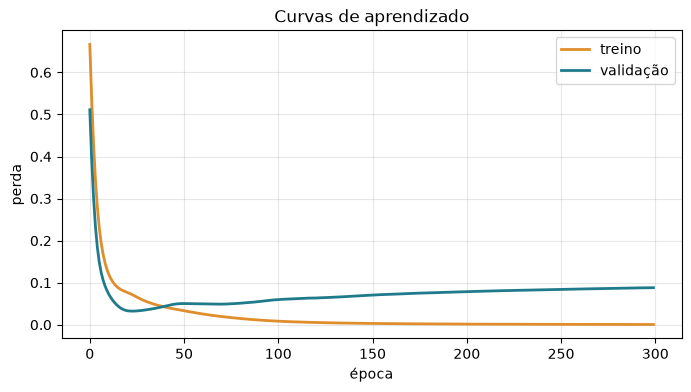

época com menor perda de validação: 23
acurácia -> treino: 100.0% | validação: 97.4%


In [ ]:
torch.manual_seed(42)
rede = nn.Sequential(nn.Linear(30, 64), nn.ReLU(), nn.Linear(64, 1))
perdas_treino, perdas_valid = treinar(rede)

plt.figure(figsize=(8, 4))
plt.plot(perdas_treino, color=LARANJA, linewidth=2, label="treino")
plt.plot(perdas_valid, color=AZUL, linewidth=2, label="validação")
plt.xlabel("época"); plt.ylabel("perda"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Curvas de aprendizado")
plt.show()

melhor_epoca = int(np.argmin(perdas_valid))
print("época com menor perda de validação:", melhor_epoca)
print(f"acurácia -> treino: {acuracia(rede, X_treino, Y_treino):.1%} | validação: {acuracia(rede, X_valid, Y_valid):.1%}")

### Como ler as curvas

| O que se vê | Diagnóstico | O que fazer |
|---|---|---|
| as duas perdas altas e próximas | **subajuste**: o modelo é simples demais ou treinou pouco | rede maior, mais épocas |
| as duas caem e ficam próximas | **bom ajuste** | — |
| treino continua caindo, validação para de cair ou **sobe** | **sobreajuste**: o modelo está decorando o treino | menos épocas, rede menor, regularização (próxima aula) |

Aqui, a perda de treino cai sem parar, mas a de validação atinge um mínimo cedo e depois volta a subir: um sinal claro de **sobreajuste**. A rede acerta 100% do treino, mas isso não se repete na validação.

---
## 4. Usando a validação para escolher o modelo
---

Vamos comparar algumas opções de **tamanho da rede** e **número de épocas**. Para cada combinação, treinamos e medimos a acurácia **na validação**.

In [ ]:
resultados = []
for neuronios in [2, 16, 64]:
    for epocas in [20, 100, 300]:
        torch.manual_seed(42)
        modelo = nn.Sequential(nn.Linear(30, neuronios), nn.ReLU(), nn.Linear(neuronios, 1))
        treinar(modelo, epocas=epocas)
        acc_val = acuracia(modelo, X_valid, Y_valid)
        resultados.append((neuronios, epocas, acc_val))
        print(f"{neuronios:3d} neurônios | {epocas:3d} épocas | acurácia na validação = {acc_val:.1%}")

  2 neurônios |  20 épocas | acurácia na validação = 92.1%
  2 neurônios | 100 épocas | acurácia na validação = 99.1%
  2 neurônios | 300 épocas | acurácia na validação = 98.2%
 16 neurônios |  20 épocas | acurácia na validação = 98.2%
 16 neurônios | 100 épocas | acurácia na validação = 97.4%
 16 neurônios | 300 épocas | acurácia na validação = 97.4%
 64 neurônios |  20 épocas | acurácia na validação = 99.1%
 64 neurônios | 100 épocas | acurácia na validação = 97.4%


 64 neurônios | 300 épocas | acurácia na validação = 97.4%


In [ ]:
melhor = max(resultados, key=lambda r: r[2])      # maior acurácia de validação
print("melhor configuração:", melhor[0], "neurônios e", melhor[1], "épocas")

melhor configuração: 2 neurônios e 100 épocas


Repare que as diferenças são pequenas (a validação tem só 114 exames, e cada erro a mais muda a acurácia em quase 1 ponto). Quando há empate, prefira o modelo **mais simples**.

### A prova final: o teste

Escolhida a configuração, treinamos o modelo final e o avaliamos **uma única vez** no teste.

In [ ]:
torch.manual_seed(42)
modelo_final = nn.Sequential(nn.Linear(30, melhor[0]), nn.ReLU(), nn.Linear(melhor[0], 1))
treinar(modelo_final, epocas=melhor[1])

print(f"acurácia no teste: {acuracia(modelo_final, X_teste, Y_teste):.1%}")

acurácia no teste: 96.5%


---
## 5. Além da acurácia: que tipo de erro o modelo comete?
---

Em um diagnóstico, os dois erros possíveis **não** têm o mesmo peso:

- **falso positivo**: dizer "maligno" para um caso benigno → exames extras, preocupação;
- **falso negativo**: dizer "benigno" para um caso maligno → um câncer não tratado.

A **matriz de confusão** conta cada tipo de acerto e de erro.

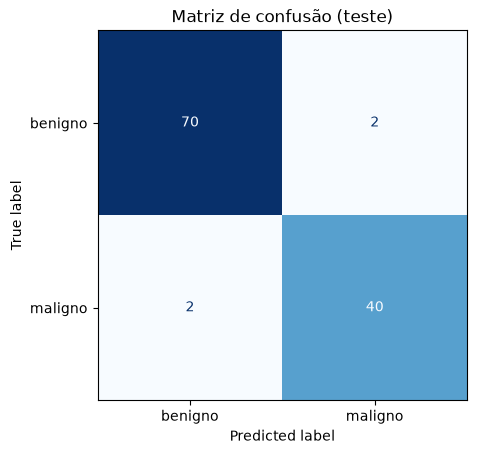

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

with torch.no_grad():
    prob_teste = torch.sigmoid(modelo_final(X_teste)).flatten().numpy()

previsto = (prob_teste > 0.5).astype(int)

matriz = confusion_matrix(y_te, previsto)
ConfusionMatrixDisplay(matriz, display_labels=["benigno", "maligno"]).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão (teste)")
plt.show()

Como ler: as **linhas** são o diagnóstico real e as **colunas**, a previsão do modelo. A diagonal são os acertos.

Duas medidas resumem a matriz do ponto de vista dos casos malignos:

- **precisão**: dos exames que o modelo chamou de malignos, quantos eram malignos? (poucos alarmes falsos)
- **revocação** (*recall*): dos casos realmente malignos, quantos o modelo encontrou? (poucos casos perdidos)

In [ ]:
from sklearn.metrics import precision_score, recall_score

print(f"precisão : {precision_score(y_te, previsto):.1%}")
print(f"revocação: {recall_score(y_te, previsto):.1%}")

precisão : 95.2%
revocação: 95.2%


---
## 6. Ajustando o limiar de decisão
---

Até agora usamos a regra "maligno se a probabilidade passar de **0,5**". Mas esse limiar é uma **escolha nossa**, não da rede. Se perder um câncer é muito pior que um alarme falso, faz sentido ser mais cauteloso e chamar de "maligno" a partir de uma probabilidade menor.

Vamos ver o efeito de vários limiares:

In [ ]:
print(f"{'limiar':>6} | {'falsos negativos':>16} | {'falsos positivos':>16} | {'revocação':>9} | {'precisão':>8}")
print("-" * 70)
for limiar in [0.9, 0.7, 0.5, 0.3, 0.1]:
    prev = (prob_teste > limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_te, prev).ravel()
    print(f"{limiar:>6} | {fn:>16} | {fp:>16} | {recall_score(y_te, prev):>9.1%} | {precision_score(y_te, prev):>8.1%}")

limiar | falsos negativos | falsos positivos | revocação | precisão
----------------------------------------------------------------------
   0.9 |                7 |                0 |     83.3% |   100.0%
   0.7 |                3 |                0 |     92.9% |   100.0%
   0.5 |                2 |                2 |     95.2% |    95.2%
   0.3 |                1 |                6 |     97.6% |    87.2%
   0.1 |                0 |               12 |    100.0% |    77.8%


- **Baixando o limiar**, o modelo encontra mais casos malignos (revocação sobe, menos falsos negativos), ao custo de mais alarmes falsos.
- **Subindo o limiar**, acontece o contrário.

Não existe limiar "certo" em geral: a escolha depende do **custo** de cada erro no problema real. Essa é uma decisão de engenharia, não de programação. (E, a rigor, o limiar também deveria ser escolhido na **validação**, não no teste.)

> **Exemplo em Engenharia de Produção:** em uma linha de inspeção, deixar passar uma peça defeituosa pode gerar um recall caro; já descartar uma peça boa custa só o material. Nesse caso, também valeria baixar o limiar.

---
## 7. De onde vem o erro? Viés e variância na prática
---

Na aula teórica vimos que o erro de teste (em regressão com mínimos quadrados) se divide em três partes:

$$ \text{erro de teste} = \text{viés}^2 + \text{variância} + \text{ruído} $$

- **viés**: o modelo é rígido demais e erra "na média";
- **variância**: o modelo muda muito de um conjunto de treino para outro;
- **ruído**: a variação natural dos dados, que nenhum modelo elimina.

Com dados reais, como os exames das seções anteriores, **não dá** para medir essas partes separadamente: não conhecemos a "resposta verdadeira" e só temos **um** conjunto de treino.

Com dados **artificiais**, dá! Nós escolhemos a função verdadeira e o ruído, e podemos sortear quantos conjuntos de treino quisermos. É exatamente assim que o livro produz a Figura 8.9.

### Gerando os dados

A função verdadeira é a mesma da Aula 03: $y = \sin(1{,}5x) + 0{,}3x$, mais um ruído com desvio-padrão $0{,}3$. Cada conjunto de treino tem apenas **15 pontos**.

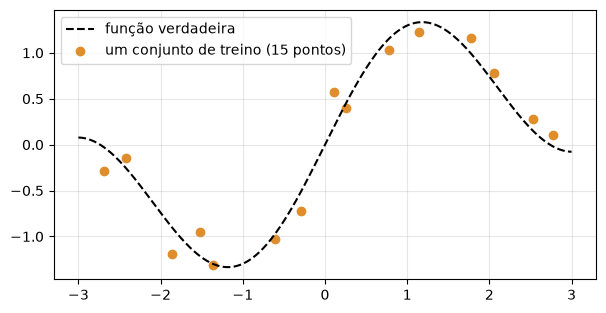

In [ ]:
def f_verdadeira(x):
    return np.sin(1.5 * x) + 0.3 * x

RUIDO = 0.3                       # desvio-padrão do ruído
rng = np.random.default_rng(42)


def sorteia_treino(n=15):
    # um ponto sorteado em cada uma de n faixas iguais de [-3, 3]
    bordas = np.linspace(-3, 3, n + 1)
    x = rng.uniform(bordas[:-1], bordas[1:])
    y = f_verdadeira(x) + rng.normal(0, RUIDO, n)
    return x, y


x_grade = np.linspace(-3, 3, 300)        # pontos para desenhar as curvas

x, y = sorteia_treino()
plt.figure(figsize=(7, 3.5))
plt.plot(x_grade, f_verdadeira(x_grade), "k--", label="função verdadeira")
plt.scatter(x, y, color=LARANJA, label="um conjunto de treino (15 pontos)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### O modelo

Usamos uma rede rasa com $D$ neurônios em que os "joelhos" da ReLU ficam em posições **fixas** e só a **última camada** é ajustada. É o "modelo simplificado" do livro. Com isso, o ajuste é exato e instantâneo (por mínimos quadrados), e podemos treinar centenas de modelos em segundos.

Quanto maior $D$, mais "dobras" a rede pode fazer: $D$ é a **capacidade** do modelo.

> Não é preciso entender os detalhes das duas funções abaixo: basta saber que `ajusta` treina o modelo e `prediz` faz previsões.

In [ ]:
def neuronios(x, D):
    # saída dos D neurônios ReLU com joelhos fixos, mais uma coluna de 1s (o viés da saída)
    joelhos = np.linspace(-3, 3, D + 1)[:-1]
    x = torch.tensor(x, dtype=torch.float64).reshape(-1, 1)
    h = torch.relu(x - torch.tensor(joelhos))
    return torch.cat([torch.ones(len(x), 1, dtype=torch.float64), h], dim=1)


def ajusta(x, y, D):
    Y = torch.tensor(y, dtype=torch.float64).reshape(-1, 1)
    return torch.linalg.lstsq(neuronios(x, D), Y).solution      # pesos da última camada


def prediz(pesos, x, D):
    return (neuronios(x, D) @ pesos).flatten().numpy()

### Muitos conjuntos de treino, muitos modelos

Vamos sortear **30 conjuntos de treino** diferentes e ajustar um modelo a cada um, para três capacidades. Em laranja, a **média** dos 30 modelos.

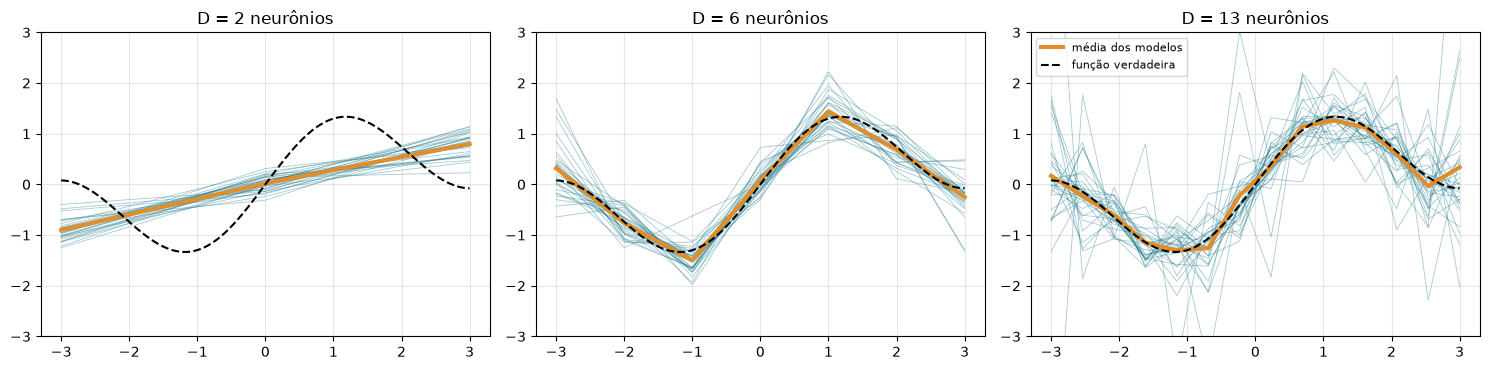

In [ ]:
conjuntos = [sorteia_treino() for _ in range(30)]

plt.figure(figsize=(15, 3.8))
for i, D in enumerate([2, 6, 13]):
    previsoes = np.array([prediz(ajusta(x, y, D), x_grade, D) for x, y in conjuntos])
    plt.subplot(1, 3, i + 1)
    for p in previsoes:
        plt.plot(x_grade, p, color=AZUL, linewidth=0.6, alpha=0.4)
    plt.plot(x_grade, previsoes.mean(axis=0), color=LARANJA, linewidth=3, label="média dos modelos")
    plt.plot(x_grade, f_verdadeira(x_grade), "k--", linewidth=1.5, label="função verdadeira")
    plt.ylim(-3, 3); plt.title(f"D = {D} neurônios"); plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

- **$D = 2$**: os modelos são parecidos entre si, mas a média fica **longe** da função verdadeira. Esse erro sistemático é o **viés**.
- **$D = 13$**: na média, o modelo acerta a forma da função, mas cada ajuste individual oscila muito, conforme os 15 pontos sorteados. Esse espalhamento é a **variância**.
- **$D = 6$**: um meio-termo.

### A nossa "Figura 8.9"

Agora medimos as duas partes para cada capacidade, com **100** conjuntos de treino:

- **viés²**: distância entre a curva média (laranja) e a função verdadeira;
- **variância**: o quanto as curvas azuis se espalham em torno da média.

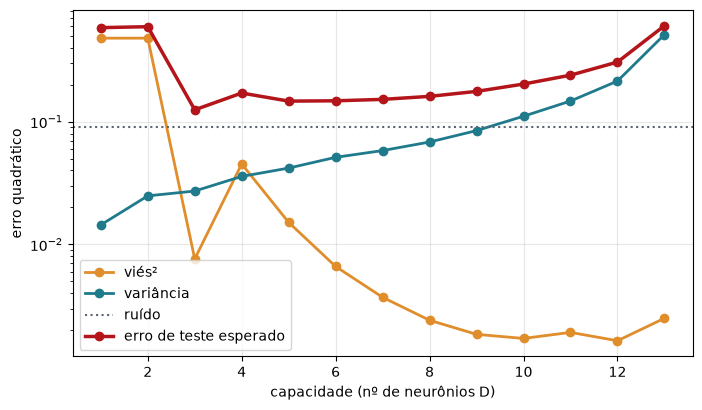

capacidade com menor erro de teste: 3


In [ ]:
capacidades = range(1, 14)
conjuntos = [sorteia_treino() for _ in range(100)]
vieses, variancias = [], []

for D in capacidades:
    previsoes = np.array([prediz(ajusta(x, y, D), x_grade, D) for x, y in conjuntos])
    media = previsoes.mean(axis=0)
    vieses.append(((media - f_verdadeira(x_grade)) ** 2).mean())
    variancias.append(previsoes.var(axis=0).mean())

vieses, variancias = np.array(vieses), np.array(variancias)
erro_total = vieses + variancias + RUIDO ** 2

plt.figure(figsize=(8, 4.5))
plt.plot(capacidades, vieses, "o-", color=LARANJA, linewidth=2, label="viés²")
plt.plot(capacidades, variancias, "o-", color=AZUL, linewidth=2, label="variância")
plt.axhline(RUIDO ** 2, color=CINZA, linestyle=":", label="ruído")
plt.plot(capacidades, erro_total, "o-", color=VERMELHO, linewidth=2.5, label="erro de teste esperado")
plt.yscale("log"); plt.xlabel("capacidade (nº de neurônios D)"); plt.ylabel("erro quadrático")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print("capacidade com menor erro de teste:", list(capacidades)[int(np.argmin(erro_total))])

O mesmo comportamento da Figura 8.9 do livro:

- aumentando a capacidade, o **viés cai** (com algumas irregularidades, porque os joelhos estão em posições fixas e encaixam melhor na curva para certos valores de $D$);
- com o conjunto de treino fixo em 15 pontos, a **variância sobe**;
- o **erro total** tem formato de **U**, com um mínimo numa capacidade intermediária;
- o **ruído** é um piso que nenhum modelo ultrapassa.

O valor exato do mínimo é diferente do livro (lá, 4 neurônios), porque a função verdadeira e os dados sorteados são outros.

> **E na prática?** Com dados reais, só enxergamos o **erro total**, por meio do erro de validação. É por isso que, na Seção 4, escolhemos o tamanho da rede comparando configurações **na validação**: estamos procurando o fundo desse U sem conseguir ver as partes separadamente.

---
## Exercícios
---

**1.** Na Seção 3, treine a rede por apenas 30 épocas. As curvas ainda mostram sobreajuste?

**2.** Na Seção 4, inclua 1 000 épocas na comparação. Qual é a acurácia de validação?

**3.** Na Seção 6, qual limiar você escolheria se cada falso negativo custasse 10 vezes mais que um falso positivo? Calcule o custo total ($10 \times FN + FP$) para cada limiar da tabela.

**4.** Troque o conjunto de dados por `load_wine` (3 tipos de vinho, 13 características). Lembre que agora são **3 classes**: a última camada deve ter 3 saídas e a perda deve ser `nn.CrossEntropyLoss()` (como no MNIST).

**5.** Na Seção 7, troque `sorteia_treino()` por `sorteia_treino(60)` (60 pontos em vez de 15) e refaça o gráfico do viés e da variância. O que acontece com a variância dos modelos grandes? E com a capacidade de menor erro?